# Analisis Pendapatan POS Tahun 2024–2025

Analisis data transaksi POS untuk mengetahui total pendapatan berdasarkan transaksi tahun 2024 dan 2025.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
df = pd.read_csv(r"C:\Users\ASUS\OneDrive\文件\analisis-transaksi-pos\dataset\paket_a_transaksi_pos_2024_2025.csv")

In [4]:
df.head()

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   id_transaksi   5030 non-null   str  
 1   tanggal        5030 non-null   str  
 2   kode_gerai     5030 non-null   str  
 3   kode_kasir     4769 non-null   str  
 4   kode_produk    5030 non-null   str  
 5   jumlah         5030 non-null   int64
 6   harga_satuan   5030 non-null   str  
 7   diskon_persen  5030 non-null   int64
 8   status         5030 non-null   str  
dtypes: int64(2), str(7)
memory usage: 353.8 KB


In [7]:
df.isnull().sum()

id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       261
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64

In [8]:
df["kode_kasir"] = df["kode_kasir"].fillna("TIDAK DIKETAHUI")

In [9]:
df.isnull().sum()

id_transaksi     0
tanggal          0
kode_gerai       0
kode_kasir       0
kode_produk      0
jumlah           0
harga_satuan     0
diskon_persen    0
status           0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(30)

In [13]:
df = df.drop_duplicates()
df.shape

(5000, 9)

In [14]:
df["harga_satuan"].value_counts().head(15)

harga_satuan
11000    197
11500    175
13500    159
12500    154
7000     148
6500     146
13000    140
12000    134
7500     132
18000    120
4500     112
10500    112
5000     106
18500     97
6000      95
Name: count, dtype: int64

In [15]:
df["harga_satuan"].value_counts().tail(20)

harga_satuan
15000,00    1
27500,00    1
14000,00    1
50500,00    1
10000,00    1
6.500       1
16.500      1
9000,00     1
13000,00    1
32500,00    1
12.000      1
12000,00    1
9500,00     1
51.500      1
53000,00    1
16.000      1
28500,00    1
53.000      1
42500,00    1
30.500      1
Name: count, dtype: int64

In [16]:
df.loc[df["harga_satuan"].str.contains(r"\.") & ~df["harga_satuan"].str.contains(","), "harga_satuan"].value_counts()

harga_satuan
28.000    3
11.000    3
13.500    3
4.500     3
20.000    3
13.000    2
7.500     2
17.000    2
11.500    2
15.000    2
10.500    2
50.500    1
20.500    1
42.500    1
18.500    1
12.500    1
42.000    1
26.500    1
23.000    1
44.000    1
15.500    1
7.000     1
6.500     1
16.500    1
12.000    1
51.500    1
16.000    1
53.000    1
30.500    1
Name: count, dtype: int64

In [17]:
df["harga_satuan"] = (
    df["harga_satuan"]
    .astype(str)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
    .astype(float)
)

In [18]:
df["harga_satuan"].head()

0    13000.0
1    21000.0
2     7500.0
3     6500.0
4     6000.0
Name: harga_satuan, dtype: float64

In [19]:
df["tanggal"] = pd.to_datetime(df["tanggal"], format="mixed", dayfirst=True)

In [20]:
df["tanggal"].head()

0   2025-02-06
1   2024-12-28
2   2024-04-09
3   2025-07-30
4   2025-03-26
Name: tanggal, dtype: datetime64[us]

In [21]:
df["tahun"] = df["tanggal"].dt.year

In [22]:
df["tahun"].value_counts().sort_index()

tahun
2024    2492
2025    2508
Name: count, dtype: int64

In [23]:
df["status"].value_counts()

status
SELESAI    4719
BATAL       191
RETUR        90
Name: count, dtype: int64

In [24]:
df.groupby("status")["jumlah"].agg(["min", "max"])

,min,max
status,,
BATAL,-4,661
RETUR,-12,12
SELESAI,-12,2375


In [25]:
df[df["jumlah"] < 0].groupby("status").size()

status
BATAL       2
RETUR       2
SELESAI    36
dtype: int64

In [26]:
df[df["jumlah"] > 100].groupby("status").size()

status
BATAL       1
SELESAI    11
dtype: int64

In [28]:
df[df["jumlah"] > 100][["id_transaksi", "jumlah", "status"]]

,id_transaksi,jumlah,status
87,TRX0243886,2375,SELESAI
244,TRX0243257,1456,SELESAI
467,TRX0243696,892,SELESAI
660,TRX0242847,661,BATAL
926,TRX0240632,1280,SELESAI
994,TRX0241002,2093,SELESAI
1035,TRX0241068,759,SELESAI
1323,TRX0240401,641,SELESAI
2414,TRX0241473,1310,SELESAI
3220,TRX0242632,746,SELESAI


In [29]:
df = df[df["jumlah"] <= 100]

In [30]:
df.shape

(4988, 10)

In [31]:
df["pendapatan"] = (
    df["jumlah"] * df["harga_satuan"] *
    (1 - df["diskon_persen"] / 100)
)

In [32]:
df.groupby("status")["pendapatan"].sum()

status
BATAL        8638200.0
RETUR        4973600.0
SELESAI    260299250.0
Name: pendapatan, dtype: float64

In [33]:
df["pendapatan_bersih"] = df["pendapatan"]

df.loc[df["status"] == "BATAL", "pendapatan_bersih"] = 0

df.loc[df["status"] == "RETUR", "pendapatan_bersih"] = (
    -df.loc[df["status"] == "RETUR", "pendapatan"].abs()
)

In [34]:
df.groupby("tahun")["pendapatan_bersih"].sum()

tahun
2024    124331850.0
2025    130601200.0
Name: pendapatan_bersih, dtype: float64

In [35]:
pendapatan = df.groupby("tahun")["pendapatan_bersih"].sum()

selisih = pendapatan.loc[2025] - pendapatan.loc[2024]

print(f"Selisih pendapatan: Rp{selisih:,.0f}")

Selisih pendapatan: Rp6,269,350


In [36]:
persentase = (selisih / pendapatan.loc[2024]) * 100

print(f"Pertumbuhan pendapatan: {persentase:.2f}%")

Pertumbuhan pendapatan: 5.04%


In [38]:
df.to_csv("data_transaksi_bersih.csv", index=False)

In [39]:
df[df["jumlah"] < 0][["id_transaksi", "jumlah", "status", "pendapatan_bersih"]]

,id_transaksi,jumlah,status,pendapatan_bersih
32,TRX0241782,-6,SELESAI,-273000.0
41,TRX0240181,-12,SELESAI,-108000.0
90,TRX0240898,-3,SELESAI,-139500.0
195,TRX0244719,-1,SELESAI,-9975.0
723,TRX0243147,-3,SELESAI,-55500.0
847,TRX0241754,-1,BATAL,0.0
855,TRX0240649,-2,SELESAI,-27000.0
864,TRX0242385,-2,SELESAI,-19000.0
1054,TRX0243253,-1,SELESAI,-26800.0
1495,TRX0241078,-12,RETUR,-145800.0


In [40]:
df.loc[
    (df["status"] == "SELESAI") & (df["jumlah"] < 0),
    "pendapatan_bersih"
] = 0

In [41]:
pendapatan = df.groupby("tahun")["pendapatan_bersih"].sum()

print("Pendapatan 2024: Rp{:,.0f}".format(pendapatan.loc[2024]))
print("Pendapatan 2025: Rp{:,.0f}".format(pendapatan.loc[2025]))

selisih = pendapatan.loc[2025] - pendapatan.loc[2024]
persentase = (selisih / pendapatan.loc[2024]) * 100

print(f"\nSelisih pendapatan: Rp{selisih:,.0f}")
print(f"Pertumbuhan: {persentase:.2f}%")

Pendapatan 2024: Rp124,973,900
Pendapatan 2025: Rp132,067,475

Selisih pendapatan: Rp7,093,575
Pertumbuhan: 5.68%


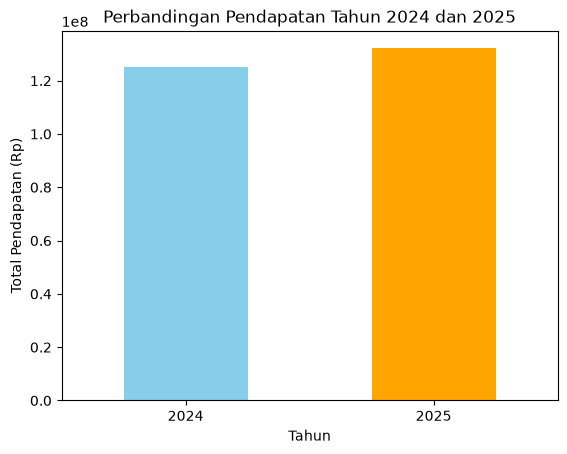

In [42]:
pendapatan.plot(kind="bar", color=["skyblue", "orange"])

plt.title("Perbandingan Pendapatan Tahun 2024 dan 2025")
plt.xlabel("Tahun")
plt.ylabel("Total Pendapatan (Rp)")
plt.xticks(rotation=0)
plt.show()

In [43]:
df.to_csv("data_transaksi_bersih.csv", index=False)

In [44]:
df = df[df["jumlah"] >= 0]

print("Jumlah data setelah dibersihkan:", len(df))

Jumlah data setelah dibersihkan: 4948


In [45]:
pendapatan = df.groupby("tahun")["pendapatan_bersih"].sum()

print("Pendapatan 2024: Rp{:,.0f}".format(pendapatan.loc[2024]))
print("Pendapatan 2025: Rp{:,.0f}".format(pendapatan.loc[2025]))

selisih = pendapatan.loc[2025] - pendapatan.loc[2024]
persentase = (selisih / pendapatan.loc[2024]) * 100

print(f"\nSelisih pendapatan: Rp{selisih:,.0f}")
print(f"Pertumbuhan: {persentase:.2f}%")

Pendapatan 2024: Rp125,119,700
Pendapatan 2025: Rp132,117,975

Selisih pendapatan: Rp6,998,275
Pertumbuhan: 5.59%


In [46]:
df.to_csv("data_transaksi_bersih.csv", index=False)